# Lista 2 (7 pkt.)

In [74]:
import string
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

## Zadanie 1. (1 pkt)

To zadanie należy wykonać ręcznie, bez używania komputera, korzystając z instrukcji z **one_time_pad.pdf**. Zaszyfruj wiadomość o treści: "NEW 15 HELICOPTERS.", za pomocą klucza: 68496 47757 10126 36660 25066. Do słów, które są w tabeli poniżej użyj odpowiednio ich kodów. Uwaga: w wiadomości jest liczba mnoga "helicopterS".

$\begin{array}{|c|c|c|c|c|c|c|c|c|c|}
\hline
CODE&A&E&I&N&O&T&&\\
0&1&2&3&4&5&6&&&\\
\hline
B&C&D&F&G&H&J&K&L&M\\
70&71&72&73&74&75&76&77&78&79\\
\hline
P&Q&R&S&U&V&W&X&Y&Z\\
80&81&82&83&84&85&86&87&88&89\\
\hline
FIG&.&:&,/'&(/)&+&-&=&REG/?&SPC\\
90&91&92&93&94&95&96&97&98&99\\
\hline
\end{array}$

$\begin{array}{|cc|cc|cc|cc|}
\hline
000&ABORT&253&DECODE&505&MILITARY&758&STREET\\
\hline
019&ACCEPT&262&DELAY&514&MONEY&767&SUBWAY\\
\hline
028&ACCESS&271&DIFFICULT&523&MONTH&776&SUCCESS\\
\hline
037&ADDRESS&280&DOCUMENT&532&MORNING&785&SUPPLY\\
\hline
046&AFFIRMATIVE&299&ENCODE&541&MORSE&794&SUPPORT\\
\hline
055&AGENT&307&EVENING&550&NEGATIVE&802&TELEPHONE\\
\hline
064&AIRPLANE&316&EXECUTE&569&NIGHT&811&TODAY\\
\hline
073&AIRPORT&325&FACTORY&578&OBSERVATION&820&TOMORROW\\
\hline
082&ANSWER&334&FAILED&587&PASSPORT&839&TRAIN\\
\hline
091&AUTHORITY&343&FERRY&596&PERSON&848&TRANSFER\\
\hline
109&BETWEEN&352&FLIGHT&604&PHOTOGRAPH&857&TRANSMIT\\
\hline
118&BORDER&361&FREQUENCY&613&POSITIVE&866&TRAVEL\\
\hline
127&BUILDING&370&HARBOUR&622&POSSIBLE&875&TRUCK\\
\hline
136&CANCEL&389&HELICOPTER&631&POWER&884&UNABLE TO\\
\hline
145&CHANGE&398&HIGHWAY&640&PRIORITY&893&URGENT\\
\hline
154&CIVILIAN&406&IDENTITY&659&PROBLEM&901&VERIFY\\
\hline
163&COMPROMISE&415&IMMEDIATE&668&QUESTION&910&WEEK\\
\hline
172&COMPUTER&424&IMPOSSIBLE&677&RADIO&929&WITHIN\\
\hline
181&CONFIRM&433&INFORMATION&686&RECEIVE&938&YESTERDAY\\
\hline
190&CONTACT&442&INSTRUCTIONS&695&RENDEZVOUS&&\\
\hline
208&COORDINATE&451&LOCATE&703&REPEAT&&\\
\hline
217&COUNTRY&460&LOCATION&712&RESERVATION&&\\
\hline
226&COVERT&479&MAIL&721&ROUTINE&\\
\hline
235&CURRENT&488&MEETING&730&SATELLITE&\\
\hline
244&DANGER&497&MESSAGE&749&SHIP&\\
\hline
\end{array}$

Najpierw znaki na liczby:  

$\texttt{N  E  W     1    5        HELICOPTER S   .}$  
$\texttt{4  2  86 90 111  555 90   0389       83  91}$

  
\
Potem szyfr one time pad:
  
\
$\texttt{KEYID 42869 01115 55900 38983 91}$  
$\texttt{68496 47757 10126 36660 25066 07}$  
$\texttt{--------------------------------}$  
$\texttt{68496 05112 91099 29340 13927 94}$  

## Zadanie 2 (1 pkt)

To zadanie również jest do zrobienia ręcznie. Używając klucza 11454 03055 15565 17466 26950 54906 odkoduj wiadomość 11454 00572 94578 25863 84286 24376. Wykorzystaj instrukcje z one_time_pad.pdf oraz tablicę kodów z Zadania 1.

Dodajemy klucz do cyfr wiadomości:


$\texttt{11454 00572 94578 25863 84286 24376}$  
$\texttt{11454 03055 15565 17466 26950 54906}$  
$\texttt{-----------------------------------}$  
$\texttt{KEYID 03527 09033 32229 00136 78272}$  


\
Rozbijamy cyfry na znaki lub kody:


$\texttt{0352    70   90 333 222 90  0136   78 2 72}$  
$\texttt{FLIGHT  B       3   2       CANCEL L  E D}$  


\
*Flight B 32 cancelled*

## Zadanie 3. (1 pkt)

Wczytaj obrazki 'miki.png' oraz 'quest.png'.

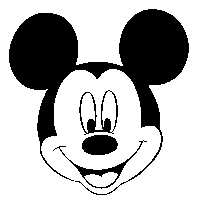

In [75]:
img1 = Image.open('miki.png').convert('L')
img1

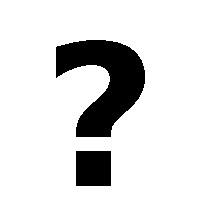

In [76]:
img2 = Image.open('quest.png').convert('L')
img2

Napisz funkcję **add_pic(img1, img2)**, która przyjmuje dwa obrazki i je dodaje piksel po pikselu za pomocą XOR, czyli **biały+biały=czarny, biały+czarny=biały, czarny+czarny=czarny**. Warto wykorzystać to, że **np.array(img)** zwraca tablicę, z wartościami 255 dla białych pikseli i 0 dla czarnych, aby zamienić tablicę z powrotem na obraz należy użyc **Image.fromarray()** przy czym tablica musi być typu **np.uint8** czyli tworząc tablicę podajemy typ: **np.array([1,2,3,4], dtype=np.uint8)**. Funkcja ma zwracać obrazek.

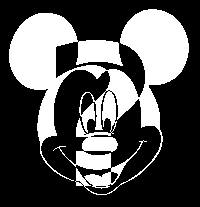

In [77]:
def add_pic(img1, img2):
  a = np.array(img1, dtype=np.uint8)
  b = np.array(img2, dtype=np.uint8)
  return Image.fromarray(np.bitwise_xor(a, b)).convert('L')

add_pic(img1, img2)

Wygeneruj (pseudo)losowy klucz, czyli obrazek z losowymi białymi i czarnymi pikselami, użyj **np.random**. Następnie zaszyfruj tym kluczem, za pomocą **add_pic**, oba obrazki **img1** i **img2**. Zauważ, że oba obrazki wyglądają na dobrze zaszyfrowane, zobacz jednak co się wydarzy kiedy dodasz do siebie te zaszyfrowane obrazki.

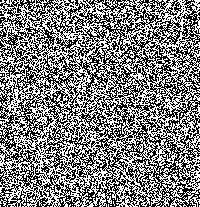

In [78]:
def random_pic(width=207, height=200):
  arr = np.random.randint(0, 2, size=(width, height), dtype=np.uint8) * 255
  return Image.fromarray(arr).convert('L')

random_noise_key = random_pic()
random_noise_key

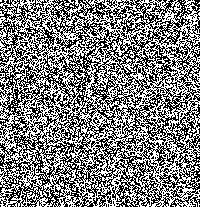

In [79]:
img1_with_noise = add_pic(img1, random_noise_key)
img1_with_noise

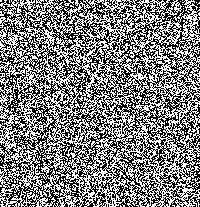

In [80]:
img2_with_noise = add_pic(img2, random_noise_key)
img2_with_noise

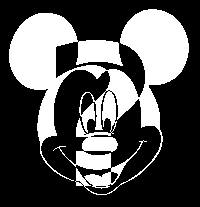

In [81]:
add_pic(img1_with_noise, img2_with_noise)

Szyfrowanie XOR tym samym kluczem-szumem pozwala na odkodowanie obrazków przez ich dodanie - klucz XOR klucz się zeruje.

## Zadanie 4 (2 pkt.)

Zmienne ***msg1_enc*** oraz ***msg2_enc*** zawierają dwie zaszyfrowane wiadomości, w języku angielskim.

In [82]:
msg1_enc = '\x1e\x17\x0c\x12\x1b\x08\x0cf\x0e\x11x\x1a\x1c\x12o\x06\x18\x1f\x17\x03\x10\x01fkh\x1f\x08'
msg2_enc = '\x0b\ni\x07\x1c\x02k\x1f\x16e\x01\x0b\x07\x03\n\x15\x15\x0c\x1el\x07\x03\x03\x16\x01\x01\x02'

Wiadomo, że zostały zaszyfrowane tym samym kluczem, możemy to wykorzystać do odszyfrowania ich. W tym zadaniu konwencja zamiany liter na liczby i ich dodawania jest inna, niż w poprzednich. Znaki zamieniamy na liczby kodujące te znaki w **Unicode**, czyli za pomocą **ord()**, następnie dodajemy je do siebie za pomocą XOR na poziomie bitów, czyli za pomocą **^**. Napisz funkcję **add_str(msg1, msg2)**, które przyjmuje dwa teksty i zwraca tekst będący sumą tych tekstów zgodnie z powyższą konwencją.

In [83]:
def add_str(msg1, msg2):
  msg_added = ""
  for c1, c2 in zip(msg1, msg2):
    msg_added += chr(ord(c1) ^ ord(c2))
  return msg_added

added = add_str(msg1_enc, msg2_enc)
added

'\x15\x1de\x15\x07\ngy\x18ty\x11\x1b\x11e\x13\r\x13\to\x17\x02e}i\x1e\n'

Zauważmy, że jeżeli dwie wiadomości są zaszyfrowane tym samym kluczem to dodanie ich do siebie sprawia, że dostaniemy sumę wiadomości bez klucza. Poza tym zauważmy, że jeżeli znamy jakieś słowo występujące w którejś z wiadomości i je dodamy do sumy tych wiadomości w odpowiednim miejscu to w wyniku dostaniemy poprawne słowo z drugiej wiadomości. Zatem metoda łamania tych wiadomości jest następująca, zgadujemy jakie słowo może być w którejś z wiadomości, dodajemy je w różnych miejscach sumy wiadomości i patrzymy czy powstaje coś co może być fragmentem poprawnego tekstu, następnie na podstawie tego fragmentu zgadujemy większą pozostałą część słowa i teraz to słowo używamy do odczytania kolejnego fragmentu z pierwszej wiadomości.

Pierwsze słowo wybieramy z pośród najpopularniejszych słów w danym języku.

Najpopularniejsze angielskie słowa:
1. THE
2. BE
3. TO
4. OF
5. AND

Uwaga 1: Słowa zapisane są drukowanymi literami.

Uwaga 2: Słowa oddzialane są spacjami, zatem biorąc np. słowo THE należy sprawdzać ciąg znaków "&nbsp; THE &nbsp;", ze spacjami na początku i końcu, dzięki temu odszyfrujemy więcej znaków.

In [84]:
def word_sweep(added, word):
  allowed = set("ABCDEFGHIJKLMNOPQRSTUVWXYZ .,!?")
  for i in range(len(added) - len(word) + 1):
    fragment = add_str(added[i:i + len(word)], word)
    if all(c in allowed for c in fragment):
      print(f"{i:3d}: {fragment!r}")

In [85]:
word_sweep(added, " THE ")

  2: 'EAOOG'
 10: 'YESTE'


In [86]:
word_sweep(added, " BE ")

 19: 'OUGE'


In [87]:
word_sweep(added, " TO ")

 19: 'OCME'


In [88]:
word_sweep(added, " OF ")

 19: 'OXDE'


In [89]:
word_sweep(added, " AND ")

  2: 'ETING'
 10: 'YPUUE'


### Analiza miejsc odszyfrowanych:  
YESTE -> **yeste**rday  
ETING -> me**eting** albo gre**eting**s  
  
  
Reszta miejsc nie ma sensu

In [90]:
def guess_at(added, i, word):
    return add_str(added[i:i + len(word)], word)

In [91]:
guess_at(added, 9, " YESTERDAY ")

'T THE AIRPO'

In [92]:
guess_at(added, 0, "MEETING ")

'XX AND Y'

In [93]:
guess_at(added, 0, "GREETINGS ")


'RO PSC)>KT'

### Rozszerzając dalej:

T THE AIRPO -> a**t the airpo**rt to będą znaki na pozycjach 9 do 20 wiadomości A  
  
**meeting** rozpoczyna wiadomość A (greetings odpada - po dodaniu śmieci)
  
  
*meeting* to znaki od 0 do 7 wiadomości A, więc *meeting* stoi bezpośrednio przed *at the airport*

In [94]:
print(guess_at(added, 0, "MEETING AT THE AIRPORT "))

XX AND YY YESTERDAY EVE


**xx and yy yesterday eve**ning rozpoczyna wiadomość B

In [95]:
print(guess_at(added, 0, "XX AND YY YESTERDAY EVENING"))

MEETING AT THE AIRPORT 3 PM


In [96]:
msg_A = guess_at(added, 0, "XX AND YY YESTERDAY EVENING")
msg_B = guess_at(added, 0, msg_A)

In [97]:
print(msg_A)
print(msg_B)

MEETING AT THE AIRPORT 3 PM
XX AND YY YESTERDAY EVENING


### To już całe wiadomości
A: **Meeting at the airport 3 pm**  
B: **XX and YY yesterday evening**  

Są one długości równej `msg1_enc` i `msg2_enc`

In [98]:
print(len(msg_A) == len(msg1_enc))
print(len(msg_B) == len(msg2_enc))

True
True


Żeby znaleźć klucz, którym te wiadomośc zostały zaszyfrowane należy dodać do siebie `msg1_enc` i `msg_A` lub `msg2_enc` i `msg_B`

In [99]:
key_A = add_str(msg_A, msg1_enc)
key_B = add_str(msg_B, msg2_enc)

print(key_A == key_B)
key_A

True


'SRIFRFKFOEXNTWOGQMGLBUFXHOE'

## Zadanie 5 (2 pkt.)

W poprzednim zadaniu korzystaliśmu z faktu, że obie wiadomości były zaszyfrowane przy użyciu tego samego klucza. Jednka w praktyce nie wiemy, które i czy w ogóle, wiadomosci były zaszyfrowane przy użyciu tego samego klucza. Możemy to wykryć dokonując analizy statystycznej. Załóżmy, że dodajemy do siebie dwie wiadomości zaszyfrowane tymi samymi kluczami. Wtedy miejsca w których dostaniemy 0 (w konwencji użytej w tym zadaniu znak odpowiadający 0 w Unicode, czyli chr(0)) są miejscami w których w obu wiadomościach była ta sama litera. Jeżeli natomiast dodajemy wiadomości o różnych kluczach będziemy dostawać 0 w losowych miejscach. Zatem w pierwszym przypadku otrzymamy więcej 0.

Zatem należy wczytać wszystkie wiadomości msg1.txt, msg2.txt itd. a następnie dodać je do siebie parami, każda z każdą i policzyć odsetek 0 (tzn. znaków chr(0)) w otrzymanych sumach. Para wiadomości o wyższym niż inne odsetku będzie tą zaszyfrowaną przy u życiu tego samego klucza. Aby łatwiej zauważyć taką parę warto zilustrować sobie wyniki (odsetki 0) za pomocą **plt.imshow(X ,norm=LogNorm())** i użyć skali logarytmicznej, gdzie **X** to tablica 10 na 10 zawierająca odsetki 0 dla każdej pary wiadomości.

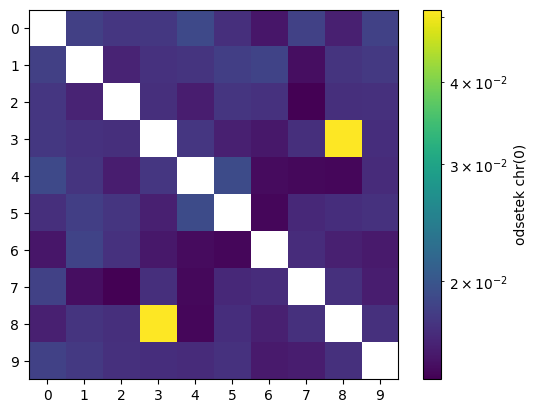

Najbardziej podejrzana para: msg3 i msg8, % = 0.0513


In [104]:
msgs = [open(f"msg{i}.txt", encoding="utf-8").read() for i in range(0, 10)]

def zero_ratio(m1, m2):
    s = add_str(m1, m2)
    return s.count(chr(0)) / len(s)

X = np.full((10, 10), np.nan)
for i in range(0, 10):
    for j in range(0, 10):
        if i != j:
            X[i, j] = zero_ratio(msgs[i], msgs[j])

plt.imshow(X, norm=LogNorm())
plt.colorbar(label="odsetek chr(0)")
plt.xticks(range(0, 10), range(0, 10))
plt.yticks(range(0, 10), range(0, 10))
plt.show()

i, j = np.unravel_index(np.nanargmax(X), X.shape)
print(f"Najbardziej podejrzana para: msg{i} i msg{j}, % = {X[i, j]:.4f}")

Pliki `msg3.txt` i `msg8.txt` są zaszyfrowane tym samym kluczem.